In [170]:
import pandas as pd
import numpy as np
import pandas_ta as pta
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sn
from matplotlib.pyplot import figure
import warnings
import statsmodels.tsa.stattools as ts
import itertools
from statsmodels.tsa.stattools import adfuller
warnings.filterwarnings('ignore', category=FutureWarning)
from datetime import datetime

In [348]:
def get_historical_data(tickers, start = "2024-01-01", end = datetime.today().strftime('%Y-%m-%d')):
    print("Data: ")
    df = yf.download(tickers, start = start, end = end)

    if isinstance(df.columns, pd.MultiIndex):
        data = df["Close"]

    else:
        data = df[["Close"]]
        data.columns = tickers

    return data

In [349]:
default_tickers = [
    "AAPL", "MSFT", "NVDA", "GOOGL", "AMZN", "META", "TSLA", "BRK-B", "JPM", "V",
    "UNH", "XOM", "JNJ", "WMT", "MA", "PG", "HD", "CVX", "MRK", "ABBV",
    "COST", "LLY", "BAC", "PEP", "KO", "ADBE", "NFLX", "TMO", "MCD", "CSCO",
    "ACN", "ABT", "LIN", "DHR", "CRM", "NKE", "PFE", "WFC", "AMD", "TXN",
    "PM", "DIS", "UNP", "QCOM", "AMGN", "IBM", "CAT", "GE", "INTU", "SPGI",
    "AMAT", "ISRG", "BKNG", "NOW", "VRTX", "GILD", "MDT", "TJX", "HON", "BLK",
    "LMT", "SYK", "CB", "ADP", "C", "REGN", "MO", "VZ", "T", "PLD",
    "DE", "ADI", "CI", "BMY", "SBUX", "GEHC", "CME", "EQIX", "MDLZ", "SLB",
    "SHW", "PYPL", "GPN", "SNPS", "CDNS", "PANW", "ITW", "USB", "PNC", "ZTS",
    "CL", "TGT", "BSX", "MMM", "CSX", "NSC", "ETN", "DUK", "SO", "ICE",
    "APD", "WM", "NEM", "HUM", "EOG", "MPC", "PSX", "VLO", "OXY", "PGR",
    "MET", "AIG", "ALL", "TRV", "AON", "AJG", "COF", "AXP",
    "BNY", "STT", "NTRS", "SCHW", "MS", "GS", "TFC", "FITB", "HBAN", "RF",
    "CFG", "KEY", "ZION", "LHX", "GD", "NOC", "RTX", "BA", "HII", "TDG",
    "TXT", "LDOS", "HEI", "EMR", "PH", "ROK", "IR", "AME", "TT", "DOV",
    "XYL", "FAST", "OTIS", "CARR", "URI", "PWR", "FIX", "MLM", "VMC", "EXR",
    "PSA", "SBAC", "AMT", "CCI", "O", "SPG", "VICI", "WELL", 
    "MAA", "ESS", "UDR", "CPT", "ARE", "BXP", "KIM", "REG", "FRT", "HST",
    "AVGO", "MU", "LRCX", "KLAC", "SNOW", "PLTR", "CRWD", "DDOG", "NET", "ZS",
    "UBER", "ABNB", "SHOP", "SPOT", "TTWO", "INTC", "PYPL", "F"
]

In [350]:
def pairs_trading(tickers = False, start = False, end = False, dt = default_tickers):
    # getting our close prices for either default 193 stocks or chosen stocks
    if tickers == False:
        dataframe = get_historical_data(dt)
        
    else:
        if start != False and end != False:
            dataframe = get_historical_data(tickers, start = start, end = end)
        elif start!= False and end == False:
            dataframe = get_historical_data(tickers, start = start)
        elif start == False and end != False:
            dataframe = get_historical_data(tickers, end = end)
        else:
            dataframe = get_historical_data(tickers)
            
        

    # normalising our value to make the system more valid
    real = dataframe.copy
    dataframe = (dataframe/dataframe.iloc[0]) *100


    # doing the cointegration tests on all combinations of stocks
    results = []
    columns = dataframe.columns

    
    i = 0
    for stock1, stock2 in itertools.combinations(columns, 2):
        score, pvalue, _ = ts.coint(dataframe[stock1], dataframe[stock2])
        spread = adfuller(dataframe[stock1]-dataframe[stock2])[1]
        ratio = adfuller(dataframe[stock1]/dataframe[stock2])[1]
        ratio_series = dataframe[stock1]/dataframe[stock2]
        results.append({
            "Stock 1": stock1,
            "Stock 2": stock2,
            "Score": score,
            "P-Value": pvalue*100,
            "Spread P-Value": spread*100,
            "Ratio P_Value": ratio*100,
            "Base Ratio (latest)": (dataframe[stock1]/dataframe[stock2]).iloc[-1],
            "Z score (latest)" : (ratio_series.iloc[-1] - ratio_series.mean())/ratio_series.std()

        
        })
        
    # filtering out combinations that dont pass the threshold 
    results =  pd.DataFrame(results)
    results = results.loc[results["P-Value"] <= 5]
    i = 0
    graph_index = []
    for index, row in results.iterrows():
        graph_index.append(f"{i} | {i+6}")
        i +=7

    results["Locate Graphs"] = graph_index
        

    

    if results.empty:
        return "No signals"

   

    # getting plots for the combinations we will be choosing to make us understand visually thier content

    saved_plots = []
    for index, row in results.iterrows():
        stock1 = row["Stock 1"]
        stock2 = row["Stock 2"]

        ratio = dataframe[stock1]/dataframe[stock2]
        z_score = (ratio-ratio.mean())/ratio.std()

        ratios_5sma = ratio.rolling(window = 5, center = False).mean()
        ratios_20sma = ratio.rolling(window = 20, center = False).mean()
        std_20_sma = ratio.rolling(window = 20).std()
    
        ratio_ema3 = ratio.ewm(span = 3, adjust = False).mean()
        ratio_ema20 = ratio.ewm(span = 20).mean()
        std_20_ema = ratio.ewm(span = 20).std()
    
        window = 20
        
        sma_mean = ratio.rolling(window=window).mean()
        sma_std = ratio.rolling(window=window).std()
        z_score_sma = (ratios_5sma - sma_mean) / (sma_std + 1e-6)
    
        ema_fast = ratio.ewm(span=3, adjust=False).mean()
        ema_slow = ratio.ewm(span=30, adjust=False).mean()
    
        ema_spread = ema_fast - ema_slow
        ema_spread_mean = ema_spread.rolling(window = window).mean()
        ema_spread_std = ema_spread.rolling(window=window).std()
        z_score_ema = (ema_spread - ema_spread_mean) / (ema_spread_std + 1e-6)

       
        
    
        fig, ax = plt.subplots(figsize=(8, 4), dpi=200)
    
        ax.plot(dataframe[stock1], label = stock1)
        ax.plot(dataframe[stock2], label = stock2)
    
        ax.set_title(f"Cointegrated Pair : {stock1} and {stock2} . The P Value for this pair is {row["P-Value"]:.4f}")
        ax.legend()
    
        saved_plots.append(fig)
        plt.close(fig)
    
        fig_ratio, ax_ratio = plt.subplots(figsize=(8, 4), dpi=200)
        ax_ratio.plot(dataframe[stock1] / dataframe[stock2], label=f"Ratio ({stock1} / {stock2})", color="purple")
        ax_ratio.axhline((dataframe[stock1] / dataframe[stock2]).mean(), color="red", linestyle="--", label="Mean")
        ax_ratio.set_title(f"Price Ratio: {stock1} / {stock2}")
        ax_ratio.legend()
    
        saved_plots.append(fig_ratio)
        plt.close(fig_ratio)
        
        
    
        fig_z_score, ax_z_score = plt.subplots(figsize = (8,4), dpi = 200)
        ax_z_score.plot(z_score, label = "Z scores of Ratio")
        ax_z_score.axhline(z_score.mean(), color = "black", label = "Mean")
        ax_z_score.axhline(1, color = "red")
        ax_z_score.axhline(2, color = "red")
        ax_z_score.axhline(-1, color = "green")
        ax_z_score.axhline(-2, color = "green")
        ax_z_score.legend(loc = "best")
        ax_z_score.set_title(f"Z scores: {stock1} and {stock2}")
    
        saved_plots.append(fig_z_score)
        plt.close(fig_z_score)
    
        fig_comp,ax_comp = plt.subplots(figsize = (8,4), dpi = 200)
        ax_comp.plot(ratio.index, ratio.values)
        ax_comp.plot(ratios_5sma.index, ratios_5sma.values)
        ax_comp.plot(ratios_20sma.index, ratios_20sma.values)
        ax_comp.legend(['Ratio', '5d Ratio MA', '20d Ratio MA'])
        ax_comp.set_xlabel('Date')
        ax_comp.set_ylabel('Ratio')
        ax_comp.set_title(f'Ratio between {stock1} and {stock2} with 5 day and 20 day Simple Moving Averages')
    
        saved_plots.append(fig_comp)
        plt.close(fig_comp)
    
        fig_comp_ema,ax_comp_ema = plt.subplots(figsize = (8,4), dpi = 200)
        ax_comp_ema.plot(ratio.index, ratio.values)
        ax_comp_ema.plot(ratio_ema3.index, ratio_ema3.values)
        ax_comp_ema.plot(ratio_ema20.index, ratio_ema20.values)
        ax_comp_ema.legend(['Ratio', '3d Ratio EMA', '20d Ratio EMA'])
        ax_comp_ema.set_xlabel('Date')
        ax_comp_ema.set_ylabel('Ratio')
        ax_comp_ema.set_title(f'Ratio between {stock1} and {stock2} with 3 day and 20 day Exponentially weighted Moving Averages')
    
        saved_plots.append(fig_comp_ema)
        plt.close(fig_comp_ema)
    
        ff,fx = plt.subplots(figsize = (8,4), dpi = 200)
        fx.plot(z_score_sma)
        fx.axhline(0, color='black')
        fx.axhline(1, color='red', linestyle='--')
        fx.axhline(1.25, color='red', linestyle='--')
        fx.axhline(-1, color='green', linestyle='--')
        fx.axhline(-1.25, color='green', linestyle='--')
        fx.legend(['Rolling Ratio z-score', 'Mean', '+1','+1.25','-1','-1.25'], loc = "upper right")
        fx.set_title(f"Rolling ratio Z scores (SMA) of {stock1} and {stock2}")
    
        saved_plots.append(ff)
        plt.close(ff)
    
        ff1,fx1 = plt.subplots(figsize = (8,4), dpi = 200)
        fx1.plot(z_score_ema)
        fx1.axhline(0, color='black')
        fx1.axhline(1, color='red', linestyle='--')
        fx1.axhline(1.25, color='red', linestyle='--')
        fx1.axhline(-1, color='green', linestyle='--')
        fx1.axhline(-1.25, color='green', linestyle='--')
        fx1.legend(['Rolling Ratio z-score', 'Mean', '+1','+1.25','-1','-1.25'], loc = "upper right")
        fx1.set_title(f"Rolling ratio Z scores (EMA) of {stock1} and {stock2}")
    
        saved_plots.append(ff1)
        plt.close(ff1)
            
        
    return results, saved_plots
    

    

    
    

In [351]:
tickers = ["AAPL", "ALL", "AMD", "ASML", "CI", "GD", "IBM", "PFG", "PLTR", "QCOM", "TSM"]

In [352]:
crypto_tickers = [
    "BTC-USD",   # Bitcoin
    "ETH-USD",   # Ethereum
    "SOL-USD",   # Solana
    "XRP-USD",   # XRP
    "DOGE-USD",  # Dogecoin
    "ADA-USD",   # Cardano
    "AVAX-USD",  # Avalanche
    "LINK-USD",  # Chainlink
    "DOT-USD",   # Polkadot
    "LTC-USD",   # Litecoin
    "BCH-USD",   # Bitcoin Cash
    "ATOM-USD",  # Cosmos
    "AAVE-USD",  # Aave
    "ETC-USD",   # Ethereum Classic
    "XLM-USD",   # Stellar
    "HBAR-USD",  # Hedera
    "NEAR-USD",  # NEAR Protocol
    "ALGO-USD",  # Algorand
    "FIL-USD"    # Filecoin
]

In [353]:
signals = pairs_trading(tickers)

Data: 


[*********************100%***********************]  11 of 11 completed


In [354]:
sorted_signals = signals[0].sort_values(by = "Z score (latest)", ascending = True)
graphs = signals[1]

In [355]:
sorted_signals

,Stock 1,Stock 2,Score,P-Value,Spread P-Value,Ratio P_Value,Base Ratio (latest),Z score (latest),Locate Graphs
36,CI,PFG,-3.610478,2.377958,87.427892,73.254401,0.625528,-1.568168,28 | 34
54,QCOM,TSM,-4.527387,0.110371,83.919451,37.646120,0.326536,-1.067116,63 | 69
44,GD,TSM,-3.357135,4.733955,72.179577,9.757518,0.374302,-1.029666,49 | 55
34,CI,GD,-3.527806,3.000880,65.073832,57.128674,0.677558,-1.027463,14 | 20
39,CI,TSM,-4.148926,0.435367,77.689437,13.157418,0.253611,-1.024455,42 | 48
18,ALL,TSM,-3.602362,2.433717,71.087420,22.552208,0.470052,-0.865470,0 | 6
46,IBM,PLTR,-3.663807,2.038281,65.979223,0.053381,0.161957,-0.809419,56 | 62
37,CI,PLTR,-4.464019,0.140243,65.594748,4.837903,0.098538,-0.715867,35 | 41
35,CI,IBM,-4.484063,0.130064,21.939256,33.065899,0.608418,-0.459558,21 | 27
23,AMD,PFG,-3.978392,0.770735,68.948670,61.570580,2.282903,1.645391,7 | 13


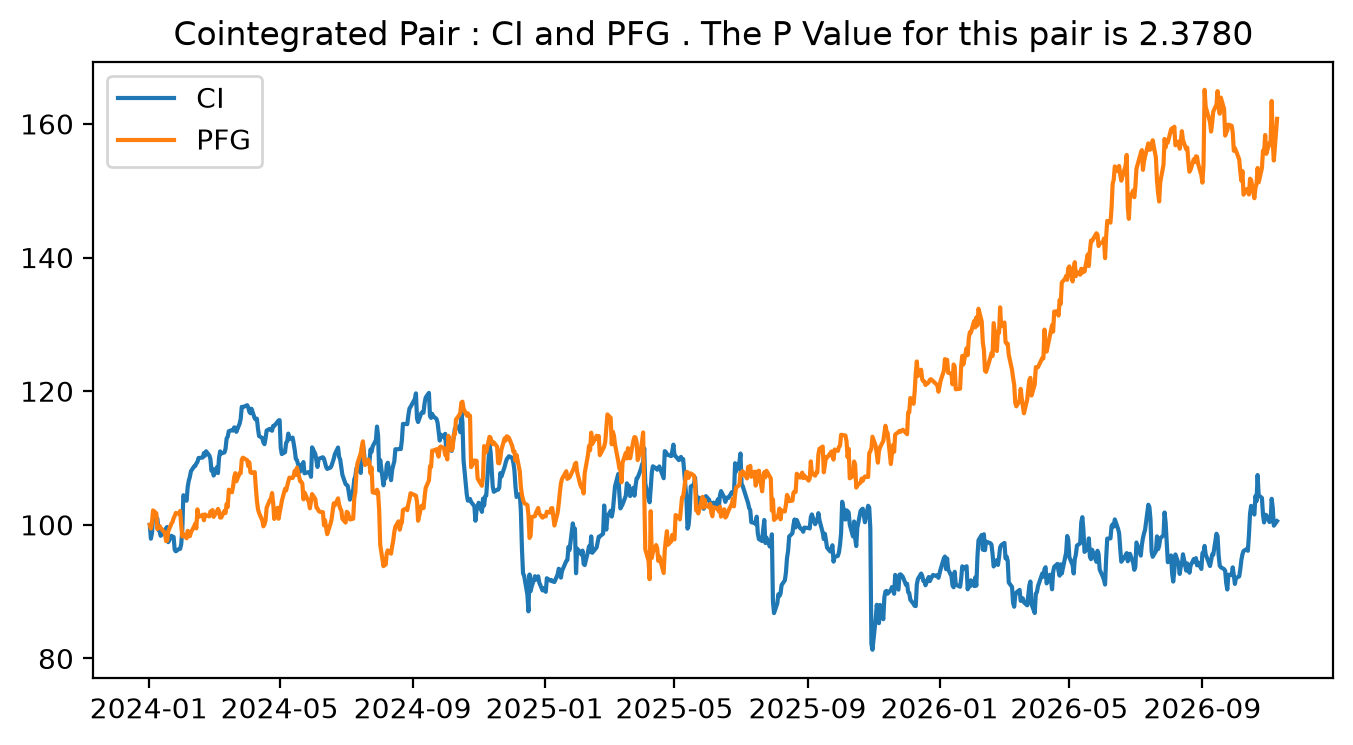

In [357]:
graphs[28]